# Bar study — L2 vs per-mode-max, on the direct sampler

Implements `SPEC_mechanism_bar_study.md`. Compares the mechanism's rejection **bar** —
`l2` (`b_m=|D_{i*}·V_m|`, current) vs `permax` (`b_m=max_i|D_i·V_m|`, covers every subject in every
mode) — on **privacy** (known-background projection advantage), **coverage**, and the **utility panel**,
across patch sizes, scales and statistics. The engine is the rejection-free **direct sampler**
(distribution-exact; it makes the higher per-mode-max bar feasible, which rejection cannot).

Frozen `mode_eigen_mech.py` is untouched — the bars are assembled additively in `bar_study.py` from its
building blocks. Empirical privacy only.

## 0 · Setup, frozen check, configuration

In [1]:
import sys, os, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
for c in [".", "work", os.path.expanduser("~/harness")]:
    if os.path.exists(os.path.join(c, "privacy_harness.py")): sys.path.insert(0, c); break
import privacy_harness as ph, mode_eigen_mech as me, tiling as T
import full_release_attacks as fra, bar_study as bs
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
FROZEN = {"privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
          "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018"}
for f, h in FROZEN.items():
    p = next((os.path.join(c, f) for c in [".", "work", os.path.expanduser("~/harness")]
              if os.path.exists(os.path.join(c, f))), None)
    if p: print(f"  {f}: {'OK' if hashlib.sha256(open(p,'rb').read()).hexdigest()==h else 'CHANGED!'}")

  privacy_harness.py: OK
  inference_eval.py: OK


In [2]:
USE_OASIS = True
N         = 40
PATCH_SIZES = {"3x3x3": (3,3,3), "5x5x5": (5,5,5), "7x7x7": (7,7,7)}
STATS     = ["mean", "median", "variance"]
BARS      = ["l2", "permax"]
TARGETS   = ["istar", "worst"]              # istar = control (covered); worst = discriminating
SCALES    = [1, 2, 3, 5, 8, 12]             # coarse first pass (the privacy lever)
for _v in ("OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS","NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
from joblib import Parallel, delayed
N_JOBS = 16; SEED = 0
SIZE = "full" if USE_OASIS else "fast"
BUDG = dict(full=dict(n_trials=4000, n_rel=200), fast=dict(n_trials=1500, n_rel=60))[SIZE]
print(f"bars={BARS} targets={TARGETS} scales={SCALES} patches={list(PATCH_SIZES)} | {SIZE}")

bars=['l2', 'permax'] targets=['istar', 'worst'] scales=[1, 2, 3, 5, 8, 12] patches=['3x3x3', '5x5x5', '7x7x7'] | full


In [3]:
# substrate: OASIS GM maps or portable phantom (per-patch cohort built from an ArrayBlockSource)
def gm_mask(volumes):
    from scipy import ndimage as ndi
    gm = np.asarray(volumes, float).mean(0); fin = np.isfinite(gm) & (gm > 0)
    try:
        from skimage.filters import threshold_otsu; thr = float(threshold_otsu(gm[fin]))
    except Exception: thr = float(np.percentile(gm[fin], 60))
    m = ndi.binary_fill_holes(gm > thr); lab, n = ndi.label(m)
    if n > 1:
        sz = ndi.sum(np.ones_like(lab), lab, range(1, n+1)); m = lab == (1 + int(np.argmax(sz)))
    return m & np.isfinite(gm)
if USE_OASIS:
    try:
        import tiling as _T; SUB = _T.load_oasis_volumes(n=max(N+20,100)); VOLS = SUB["volumes"]
        MASK = gm_mask(VOLS); SUBSTRATE = "OASIS gray-matter maps"
    except Exception as e:
        USE_OASIS = False; print("OASIS unavailable ->", repr(e))
if not USE_OASIS:
    SUB = T.make_phantom(shape=(24,24,20), M=2*N+20, N=N, seed=0); VOLS = SUB["volumes"]
    MASK = SUB["mask"]; SUBSTRATE = "synthetic phantom"
def cohort_at(patch):
    src = ph.ArrayBlockSource(VOLS, MASK, block_shape=patch, N=N, seed=SEED)
    return src.sample(N, np.random.default_rng(0)).reshape(N, *patch)
print(f"substrate: {SUBSTRATE} | volumes {VOLS.shape}")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
substrate: OASIS gray-matter maps | volumes (100, 91, 109, 91)


## 1 · Validation gate (must pass before trusting results)

(a) the direct sampler reproduces the frozen rejection mechanism's output distribution (covariance),
and (b) per-mode-max covers 100% of subject-mode influences while L2 covers less.

In [4]:
pool5 = cohort_at(PATCH_SIZES["5x5x5"]); _, D5, _ = ph.loo_artifacts(pool5, ph.pipeline_mean)
fm = me.mech_mode_eigen(*ph.loo_artifacts(pool5, ph.pipeline_mean), scale=3.0, k_check=39,
                        max_draws=500, keep_modes=True)
rr = np.random.default_rng(5); Zf = np.array([fm.sample(rr) for _ in range(5000)])
Zd = T._direct_coeffs(bs.build_modes(D5, 3.0, 39, "l2"), 5000, np.random.default_rng(6))
rel = np.linalg.norm(np.cov(Zf.T)-np.cov(Zd.T))/np.linalg.norm(np.cov(Zf.T))
print(f"(a) direct(l2) vs frozen covariance rel-diff = {rel:.4f}   {'OK' if rel < 0.08 else 'CHECK'}")
for bk in BARS:
    c = bs.bar_coverage(bs.build_modes(D5, 3.0, 39, bk))
    print(f"(b) coverage {bk:>6}: overall {c['overall']:.3f}  min-subject {c['min_subject']:.3f}")

(a) direct(l2) vs frozen covariance rel-diff = 0.0359   OK
(b) coverage     l2: overall 0.464  min-subject 0.308
(b) coverage permax: overall 1.000  min-subject 1.000


## 2 · The comparison — bar × target × scale × patch × statistic

For each cell: projection membership advantage, bar coverage, utility (rel-MSE, neighbour-corr gap,
Spearman, bias), and the analytic fallback diagnostic (not a privacy/utility factor — the direct
sampler never falls back).

In [5]:
def _job(patch_name, patch, stat):
    df = bs.run_comparison(cohort_at(patch), stat, SCALES, bars=BARS, targets=TARGETS,
                           n_trials=BUDG["n_trials"], n_rel=BUDG["n_rel"], seed=SEED)
    df.insert(0, "patch", patch_name); return df
jobs = [(nm, ps, st) for nm, ps in PATCH_SIZES.items() for st in STATS]
RES = pd.concat(Parallel(n_jobs=min(N_JOBS, len(jobs)))(delayed(_job)(nm, ps, st) for nm, ps, st in jobs),
                ignore_index=True)
# headline: coverage by bar/patch, and the L2-vs-permax advantage gap on the discriminating target
print("coverage by bar x patch (mean stat, scale=3):")
cov_tbl = RES[(RES.stat=="mean") & (RES.scale==3)].pivot_table(index="patch", columns="bar", values="coverage")
print(cov_tbl.round(3).to_string())
print("\nadvantage, target=worst (the case L2 under-covers), 5x5x5:")
w = RES[(RES.target=="worst") & (RES.patch=="5x5x5")].pivot_table(index=["stat","scale"], columns="bar", values="adv")
print(w.round(3).to_string())

coverage by bar x patch (mean stat, scale=3):
bar       l2  permax
patch               
3x3x3  0.506     1.0
5x5x5  0.464     1.0
7x7x7  0.508     1.0

advantage, target=worst (the case L2 under-covers), 5x5x5:
bar                l2  permax
stat     scale               
mean     1      0.659   0.511
         2      0.462   0.405
         3      0.348   0.307
         5      0.220   0.202
         8      0.139   0.119
         12     0.106   0.103
median   1      0.838   0.567
         2      0.634   0.469
         3      0.503   0.392
         5      0.349   0.315
         8      0.270   0.253
         12     0.230   0.232
variance 1      0.560   0.446
         2      0.475   0.390
         3      0.415   0.328
         5      0.291   0.266
         8      0.217   0.225
         12     0.184   0.184


## 3 · Frontier & privacy curves

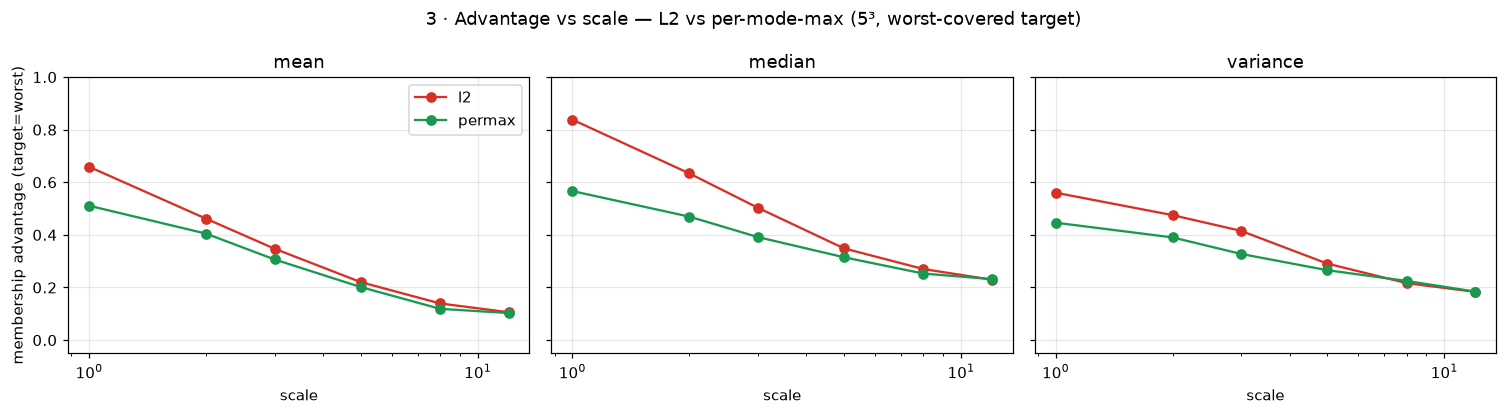

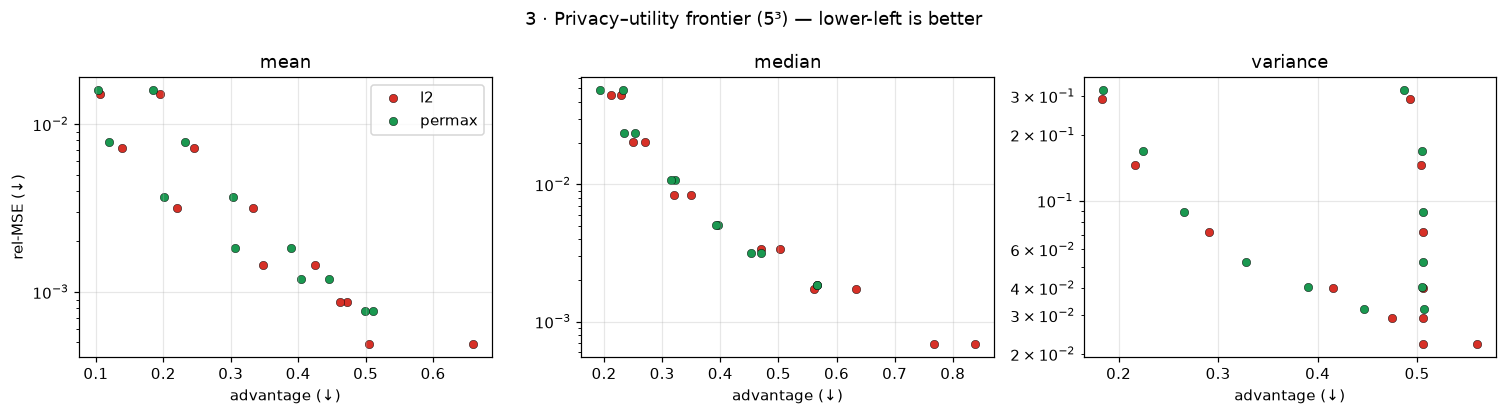

[read-off] per-mode-max should sit at equal-or-lower advantage (esp. target=worst) at a modest rel-MSE cost; its coverage is 100% vs L2's partial. Pick the bar + scale from the frontier.


In [6]:
# (i) advantage vs scale, l2 vs permax, for the discriminating target, per statistic (5x5x5)
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.8), squeeze=False, sharey=True)
for a, st in zip(axes[0], STATS):
    sub = RES[(RES.stat==st) & (RES.patch=="5x5x5") & (RES.target=="worst")]
    for bar, col in zip(BARS, ["#d73027","#1a9850"]):
        s = sub[sub.bar==bar].sort_values("scale")
        a.plot(s.scale, s.adv, "o-", color=col, label=bar)
    a.set_title(st); a.set_xlabel("scale"); a.set_xscale("log"); a.set_ylim(-0.05,1.0)
    if a is axes[0][0]: a.set_ylabel("membership advantage (target=worst)"); a.legend()
fig.suptitle("3 · Advantage vs scale — L2 vs per-mode-max (5³, worst-covered target)")
plt.tight_layout(); plt.show()

# (ii) privacy-utility frontier: advantage vs rel-MSE, coloured by bar (all configs, 5x5x5)
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.8), squeeze=False)
for a, st in zip(axes[0], STATS):
    for bar, col in zip(BARS, ["#d73027","#1a9850"]):
        s = RES[(RES.stat==st) & (RES.patch=="5x5x5") & (RES.bar==bar)]
        a.scatter(s.adv, s.rel_mse, c=col, label=bar, s=30, edgecolors="k", linewidths=0.3)
    a.set_title(st); a.set_xlabel("advantage (↓)"); a.set_yscale("log")
    if a is axes[0][0]: a.set_ylabel("rel-MSE (↓)"); a.legend()
fig.suptitle("3 · Privacy–utility frontier (5³) — lower-left is better")
plt.tight_layout(); plt.show()
print("[read-off] per-mode-max should sit at equal-or-lower advantage (esp. target=worst) at a modest "
      "rel-MSE cost; its coverage is 100% vs L2's partial. Pick the bar + scale from the frontier.")

In [7]:
print(RES[RES.target=="worst"].pivot_table(index=["stat","scale"], columns="bar",
      values=["adv","rel_mse"]).round(3).to_string())
print(RES[(RES.target=="istar") & (RES.patch=="5x5x5")]
      .pivot_table(index=["stat","scale"], columns="bar", values="adv").round(3).to_string())

                  adv        rel_mse       
bar                l2 permax      l2 permax
stat     scale                             
mean     1      0.764  0.537   0.000  0.001
         2      0.561  0.441   0.001  0.001
         3      0.437  0.361   0.001  0.002
         5      0.307  0.267   0.003  0.004
         8      0.213  0.198   0.007  0.008
         12     0.155  0.158   0.015  0.016
median   1      0.774  0.536   0.001  0.002
         2      0.556  0.468   0.002  0.003
         3      0.434  0.410   0.003  0.005
         5      0.304  0.329   0.008  0.010
         8      0.230  0.260   0.019  0.022
         12     0.198  0.213   0.042  0.046
variance 1      0.682  0.514   0.017  0.026
         2      0.569  0.450   0.023  0.033
         3      0.479  0.388   0.033  0.045
         5      0.348  0.305   0.062  0.077
         8      0.250  0.251   0.129  0.149
         12     0.206  0.202   0.261  0.288
bar                l2  permax
stat     scale               
mean     1      

## 4 · Read-off

- **Coverage**: per-mode-max covers 100% of subject-mode influences by construction; L2 covers less
  (the §2 table shows how much, per patch).
- **Privacy**: compare L2 vs per-mode-max advantage, especially for `target=worst` — the subject the L2
  bar leaves exposed. A lower per-mode-max advantage there is the coverage benefit made concrete.
- **Utility**: per-mode-max adds more noise (higher bar) → watch rel-MSE / neighbour-corr gap; the cost
  is expected to be modest and concentrated where another subject spikes.
- **Scale** remains the lever that beats the multi-mode aggregation attack; the bar fixes *coverage*,
  scale fixes *aggregation*. Choose the operating (bar, scale) from the frontier, per statistic.

*Next (separate): inference-validity on this mechanism; the full-release blended sweeps (SPEC_NB8);
and the hard-bar vs variance-inflation question for the supervisor.*